# SmartFactory AI - Etape 6 : Evaluation approfondie
Ce notebook complète le notebook 04 avec :
1. un tableau récapitulatif et le choix du meilleur modèle ;
2. l'effet de la PCA, modèle par modèle ;
3. les erreurs de chaque modèle (faux positifs, faux négatifs) ;
4. l'évaluation finale du Random Forest optimisé avec seuil ajusté ;
5. un intervalle de confiance (bootstrap) sur le test ;
6. l'analyse des pannes ratées **par mode de panne** (TWF, HDF, PWF, OSF, RNF).

Prérequis : notebook 04 exécuté (fichiers `models_original.pkl`, `models_pca.pkl`, `rf_tuned.pkl`, `rf_tuned_meta.pkl`, `resultats_classification.csv`).

## 1. Imports et chargement

In [1]:
# Correctif : relecture des modèles HistGradientBoosting (module Cython "_loss")
import sys
try:
    import sklearn._loss._loss as _cy_loss
    sys.modules.setdefault("_loss", _cy_loss)
except Exception:
    pass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             classification_report)

sns.set_theme(style="whitegrid")

BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
DATA, MODELS, FIG = BASE / "data", BASE / "models", BASE / "figures"
FIG.mkdir(exist_ok=True)
print("Projet :", BASE)

train, test = pd.read_csv(DATA / "train.csv"), pd.read_csv(DATA / "test.csv")
test_pca = pd.read_csv(DATA / "test_pca.csv")
X_test, y_test = test.drop(columns="target"), test["target"]
Xp_test = test_pca.drop(columns="target")

models_orig = joblib.load(MODELS / "models_original.pkl")
models_pca = joblib.load(MODELS / "models_pca.pkl")
rf_tuned = joblib.load(MODELS / "rf_tuned.pkl")
meta = joblib.load(MODELS / "rf_tuned_meta.pkl")
THR = meta["threshold"]
results = pd.read_csv(DATA / "resultats_classification.csv")

print("Test :", X_test.shape, "| pannes :", int(y_test.sum()), f"({y_test.mean()*100:.2f} %)")
print("Seuil optimisé du Random Forest :", round(THR, 3))

Projet : c:\Users\ghait\Desktop\Projet Python
Test : (2000, 9) | pannes : 68 (3.40 %)
Seuil optimisé du Random Forest : 0.503


## 2. Tableau récapitulatif et meilleur modèle
Le choix du meilleur modèle se fait sur la **validation croisée** (pas sur le test) : le test reste un juge impartial.

In [2]:
cols = ["Modèle", "Variante", "Recall", "Precision", "F1", "PR-AUC", "ROC-AUC", "Accuracy", "CV F1", "CV PR-AUC"]
summary = results[cols].round(3).sort_values(["Variante", "CV PR-AUC"], ascending=[True, False])
display(summary)

orig = results[results["Variante"] == "Originales"]
best = orig.loc[orig["CV PR-AUC"].idxmax()]
print(f"\nMeilleur modèle (CV PR-AUC, variables originales) : {best['Modèle']}")
print(f"  CV PR-AUC = {best['CV PR-AUC']:.3f} | F1 test = {best['F1']:.3f} | Recall test = {best['Recall']:.3f}")

# Ecart CV / test : signal de sur-apprentissage
gap = results.assign(**{"Ecart F1 (CV - test)": (results["CV F1"] - results["F1"]).round(3)})
display(gap[["Modèle", "Variante", "CV F1", "F1", "Ecart F1 (CV - test)"]].round(3))

,Modèle,Variante,Recall,Precision,F1,PR-AUC,ROC-AUC,Accuracy,CV F1,CV PR-AUC
4,Random Forest,Originales,0.750,0.962,0.843,0.869,0.973,0.990,0.852,0.889
5,Gradient Boosting,Originales,0.838,0.851,0.844,0.893,0.976,0.990,0.846,0.874
3,Decision Tree,Originales,0.824,0.389,0.528,0.773,0.857,0.950,0.554,0.794
2,SVM,Originales,0.926,0.303,0.457,0.629,0.972,0.925,0.462,0.687
1,KNN,Originales,0.324,0.880,0.473,0.605,0.889,0.976,0.420,0.599
0,Logistic Regression,Originales,0.882,0.178,0.296,0.434,0.939,0.858,0.272,0.458
10,Random Forest,PCA,0.397,0.711,0.509,0.612,0.956,0.974,0.458,0.637
11,Gradient Boosting,PCA,0.721,0.471,0.570,0.626,0.965,0.963,0.590,0.622
8,SVM,PCA,0.853,0.241,0.375,0.478,0.959,0.904,0.397,0.542
7,KNN,PCA,0.294,0.769,0.426,0.535,0.878,0.973,0.418,0.524



Meilleur modèle (CV PR-AUC, variables originales) : Random Forest
  CV PR-AUC = 0.889 | F1 test = 0.843 | Recall test = 0.750


,Modèle,Variante,CV F1,F1,Ecart F1 (CV - test)
0,Logistic Regression,Originales,0.272,0.296,-0.024
1,KNN,Originales,0.420,0.473,-0.053
2,SVM,Originales,0.462,0.457,0.005
3,Decision Tree,Originales,0.554,0.528,0.025
4,Random Forest,Originales,0.852,0.843,0.009
5,Gradient Boosting,Originales,0.846,0.844,0.002
6,Logistic Regression,PCA,0.150,0.161,-0.011
7,KNN,PCA,0.418,0.426,-0.008
8,SVM,PCA,0.397,0.375,0.022
9,Decision Tree,PCA,0.364,0.307,0.056


## 3. Effet de la PCA, modèle par modèle
Δ = (PCA) − (variables originales). Une valeur **négative** signifie que la PCA dégrade le modèle.

,Δ Recall,Δ F1,Δ PR-AUC
Modèle,,,
Decision Tree,-0.044,-0.221,-0.354
Gradient Boosting,-0.118,-0.275,-0.267
KNN,-0.029,-0.048,-0.069
Logistic Regression,-0.088,-0.136,-0.247
Random Forest,-0.353,-0.334,-0.257
SVM,-0.074,-0.081,-0.151


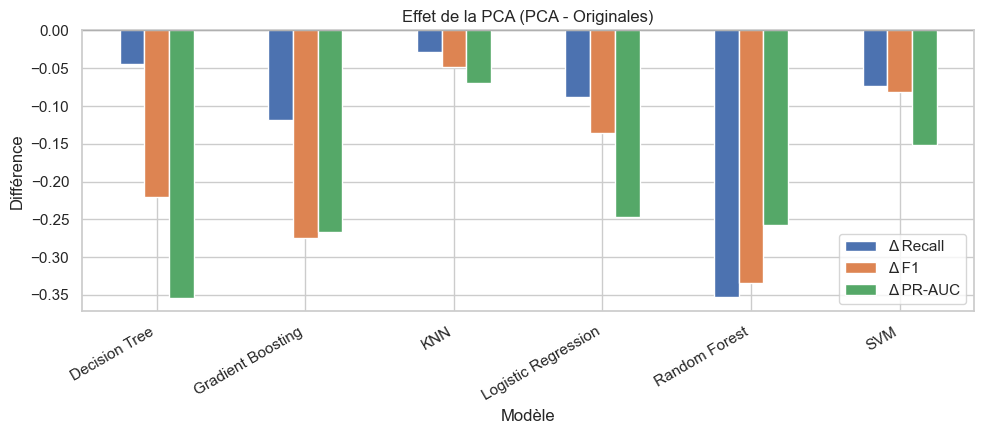

Modèles améliorés par la PCA (Δ F1 > 0) : []
Modèles dégradés par la PCA (Δ F1 < 0) : ['Decision Tree', 'Gradient Boosting', 'KNN', 'Logistic Regression', 'Random Forest', 'SVM']


In [3]:
piv = results.pivot(index="Modèle", columns="Variante", values=["Recall", "F1", "PR-AUC"])
delta = pd.DataFrame({m: piv[m]["PCA"] - piv[m]["Originales"] for m in ["Recall", "F1", "PR-AUC"]}).round(3)
delta.columns = ["Δ Recall", "Δ F1", "Δ PR-AUC"]
display(delta)

ax = delta.plot(kind="bar", figsize=(10, 4.5))
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Effet de la PCA (PCA - Originales)")
ax.set_ylabel("Différence")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIG / "effet_pca.png", dpi=200, bbox_inches="tight")
plt.show()

print("Modèles améliorés par la PCA (Δ F1 > 0) :", list(delta.index[delta["Δ F1"] > 0]))
print("Modèles dégradés par la PCA (Δ F1 < 0) :", list(delta.index[delta["Δ F1"] < 0]))

## 4. Erreurs de chaque modèle (variables originales)
- **FN** (faux négatif) : panne ratée, l'erreur la plus coûteuse.
- **FP** (faux positif) : fausse alerte, inspection inutile.

,Modèle,VP,FN (pannes ratées),FP (fausses alertes),VN
0,Logistic Regression,60,8,277,1655
1,KNN,22,46,3,1929
2,SVM,63,5,145,1787
3,Decision Tree,56,12,88,1844
4,Random Forest,51,17,2,1930
5,Gradient Boosting,57,11,10,1922
6,RF optimisé (seuil ajusté),56,12,6,1926


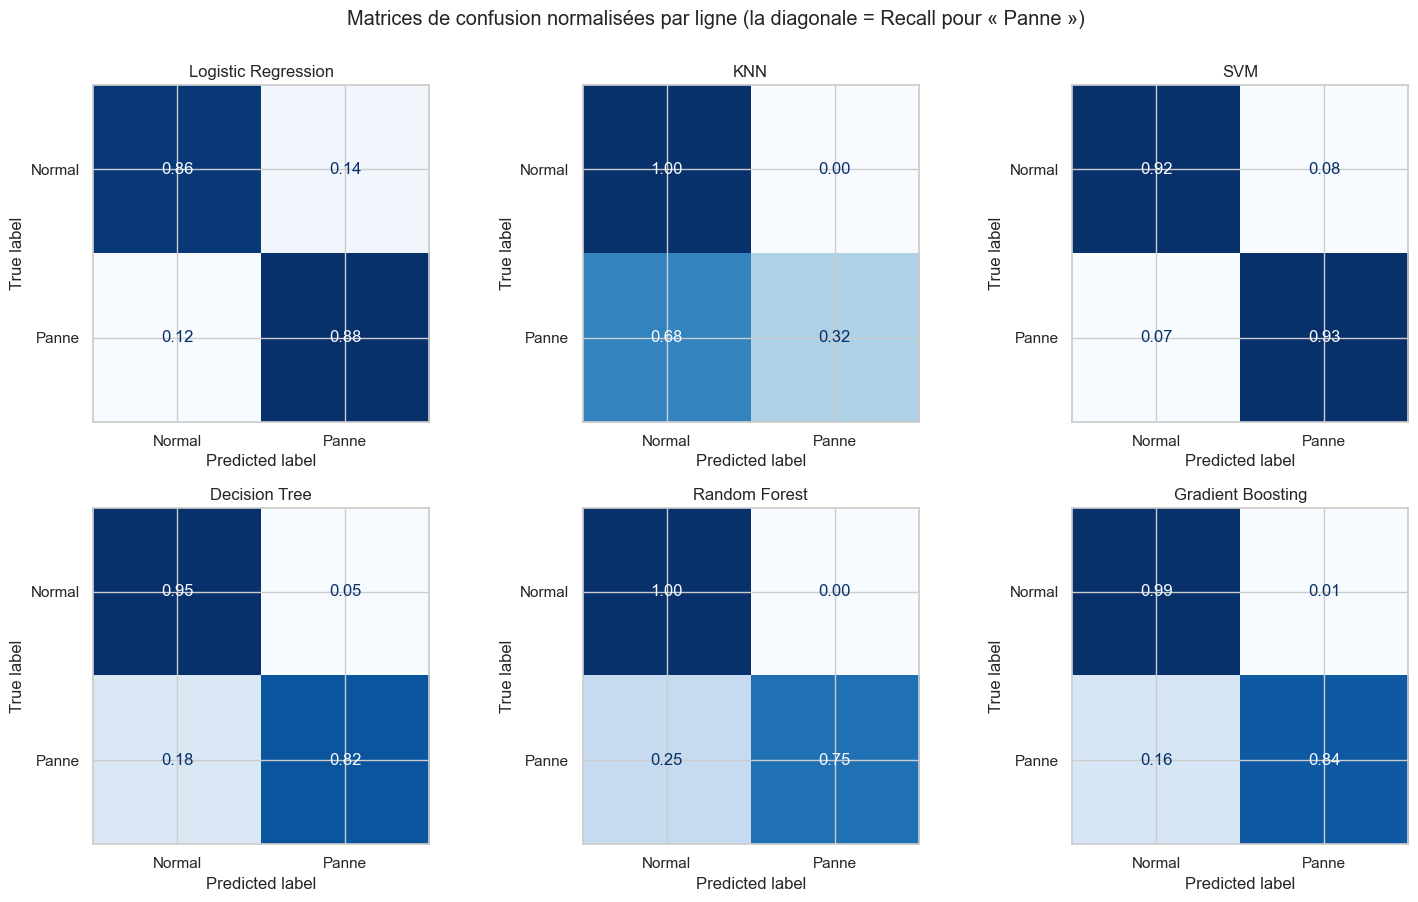

In [4]:
rows = []
for name, m in models_orig.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    rows.append({"Modèle": name, "VP": tp, "FN (pannes ratées)": fn, "FP (fausses alertes)": fp, "VN": tn})
m = rf_tuned
tn, fp, fn, tp = confusion_matrix(y_test, (m.predict_proba(X_test)[:, 1] >= THR).astype(int)).ravel()
rows.append({"Modèle": "RF optimisé (seuil ajusté)", "VP": tp, "FN (pannes ratées)": fn, "FP (fausses alertes)": fp, "VN": tn})
err = pd.DataFrame(rows)
display(err)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, model) in zip(axes.ravel(), models_orig.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax, normalize="true",
                                            display_labels=["Normal", "Panne"], colorbar=False,
                                            cmap="Blues", values_format=".2f")
    ax.set_title(name)
plt.suptitle("Matrices de confusion normalisées par ligne (la diagonale = Recall pour « Panne »)", y=1.0)
plt.tight_layout()
plt.savefig(FIG / "matrices_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Courbes ROC et Precision-Recall (test)

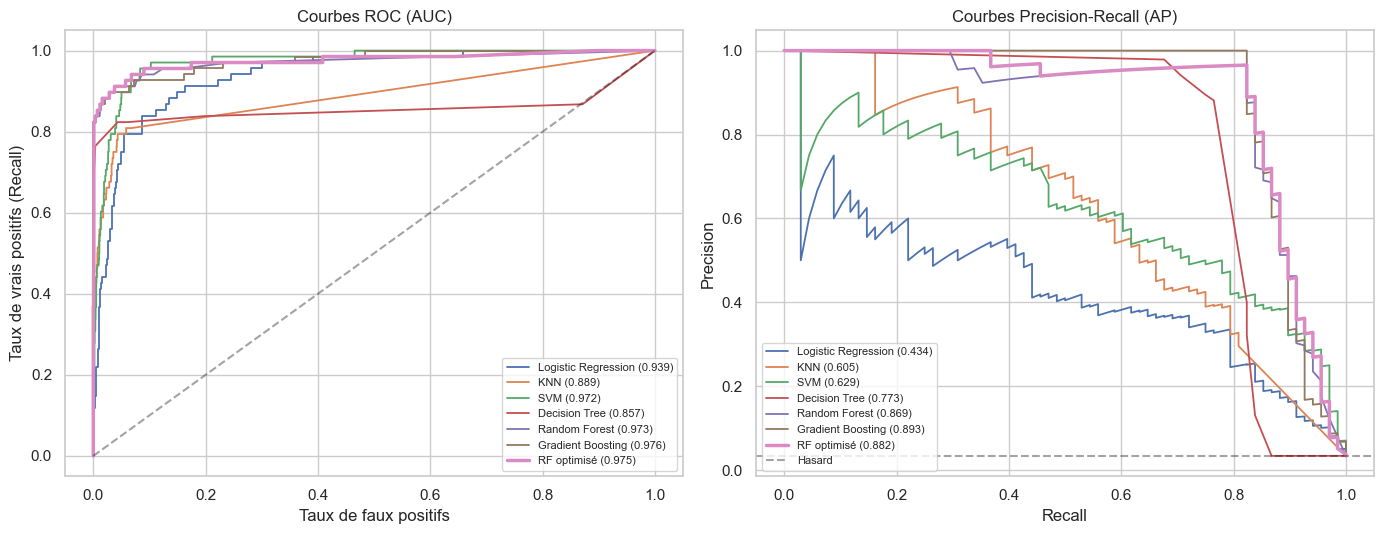

In [5]:
curves = {name: mdl.predict_proba(X_test)[:, 1] for name, mdl in models_orig.items()}
curves["RF optimisé"] = rf_tuned.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, s in curves.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    p, r, _ = precision_recall_curve(y_test, s)
    lw = 2.5 if name == "RF optimisé" else 1.3
    axes[0].plot(fpr, tpr, lw=lw, label=f"{name} ({roc_auc_score(y_test, s):.3f})")
    axes[1].plot(r, p, lw=lw, label=f"{name} ({average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(title="Courbes ROC (AUC)", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs (Recall)")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4, label="Hasard")
axes[1].set(title="Courbes Precision-Recall (AP)", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "roc_pr.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Evaluation finale : Random Forest optimisé
On compare le seuil par défaut (0,5) au seuil ajusté (choisi sur le train, sans regarder le test).

,"Seuil 0,5",Seuil ajusté (0.50)
Accuracy,0.991,0.991
Precision,0.903,0.903
Recall,0.824,0.824
F1,0.862,0.862
ROC-AUC,0.975,0.975
PR-AUC,0.882,0.882


              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      1932
       Panne       0.90      0.82      0.86        68

    accuracy                           0.99      2000
   macro avg       0.95      0.91      0.93      2000
weighted avg       0.99      0.99      0.99      2000



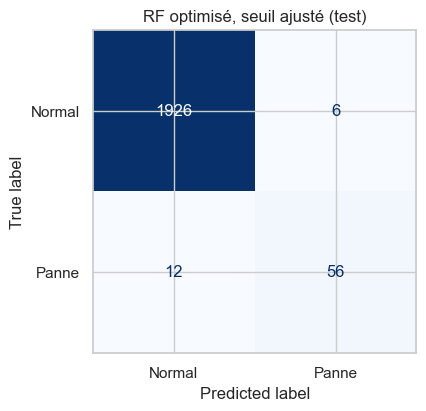

In [6]:
score = rf_tuned.predict_proba(X_test)[:, 1]
pred_def = (score >= 0.5).astype(int)
pred_thr = (score >= THR).astype(int)

def metrics(y, pred, score):
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score)}

final = pd.DataFrame({"Seuil 0,5": metrics(y_test, pred_def, score),
                      f"Seuil ajusté ({THR:.2f})": metrics(y_test, pred_thr, score)}).round(3)
display(final)
print(classification_report(y_test, pred_thr, target_names=["Normal", "Panne"]))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred_thr, display_labels=["Normal", "Panne"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title("RF optimisé, seuil ajusté (test)")
plt.savefig(FIG / "confusion_finale.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Compromis precision / recall selon le seuil (illustration)
Ce graphique sert à **illustrer** le compromis. Le seuil retenu reste celui choisi sur le train, jamais sur le test.

,Seuil,Precision,Recall,F1,Alertes,Pannes ratées
0,0.1,0.328,0.926,0.485,192,5
1,0.2,0.453,0.912,0.605,137,6
2,0.3,0.594,0.882,0.710,101,8
3,0.4,0.725,0.853,0.784,80,10
4,0.5,0.903,0.824,0.862,62,12
5,0.6,0.965,0.809,0.880,57,13
6,0.7,0.962,0.750,0.843,53,17
7,0.8,0.951,0.574,0.716,41,29


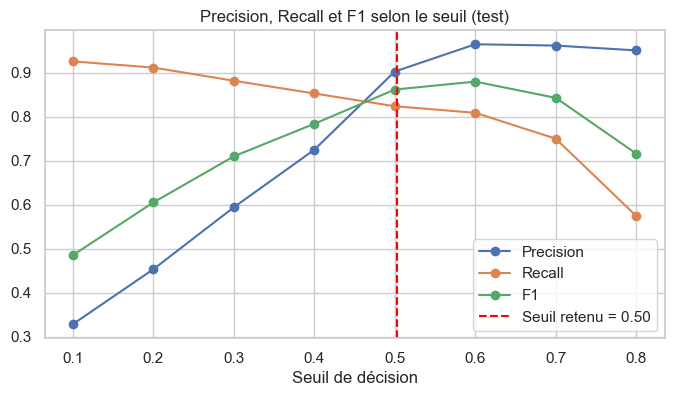

In [7]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (score >= t).astype(int)
    rows.append({"Seuil": t, "Precision": precision_score(y_test, p, zero_division=0),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p),
                 "Alertes": int(p.sum()), "Pannes ratées": int(((p == 0) & (y_test == 1)).sum())})
thr_tab = pd.DataFrame(rows).round(3)
display(thr_tab)

plt.figure(figsize=(8, 4))
for c in ["Precision", "Recall", "F1"]:
    plt.plot(thr_tab["Seuil"], thr_tab[c], marker="o", label=c)
plt.axvline(THR, color="red", linestyle="--", label=f"Seuil retenu = {THR:.2f}")
plt.xlabel("Seuil de décision"); plt.legend(); plt.title("Precision, Recall et F1 selon le seuil (test)")
plt.savefig(FIG / "seuil.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Incertitude : intervalle de confiance par bootstrap
Le test ne contient qu'un petit nombre de pannes : les métriques sont donc **incertaines**. On rééchantillonne le test 1000 fois pour estimer un intervalle à 95 %.

In [8]:
rng = np.random.default_rng(42)
y_arr = y_test.values
n = len(y_arr)
boot = {"Precision": [], "Recall": [], "F1": []}
for _ in range(1000):
    idx = rng.integers(0, n, n)
    yt, yp = y_arr[idx], pred_thr[idx]
    tp = ((yt == 1) & (yp == 1)).sum(); fp = ((yt == 0) & (yp == 1)).sum(); fn = ((yt == 1) & (yp == 0)).sum()
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0
    boot["Precision"].append(p); boot["Recall"].append(r)
    boot["F1"].append(2 * p * r / (p + r) if p + r else 0)

ci = pd.DataFrame({k: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for k, v in boot.items()},
                  index=["Moyenne", "IC 2,5 %", "IC 97,5 %"]).T.round(3)
display(ci)

,Moyenne,"IC 2,5 %","IC 97,5 %"
Precision,0.903,0.821,0.972
Recall,0.820,0.727,0.906
F1,0.859,0.785,0.917


## 9. Pannes ratées : analyse par mode de panne
On retrouve les lignes du test dans `ai4i_clean.csv` en **reproduisant le même split** (même `random_state`, même stratification). Puis on regarde quels modes de panne (TWF, HDF, PWF, OSF, RNF) le modèle détecte le mieux.

In [9]:
scaler = joblib.load(MODELS / "scaler.pkl")
feature_cols = joblib.load(MODELS / "feature_cols.pkl")
clean = pd.read_csv(DATA / "ai4i_clean.csv")

Xc, yc = clean[feature_cols], clean["Machine_failure"]
_, Xte_raw, _, _ = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=42)

same = np.allclose(scaler.transform(Xte_raw), X_test.values)
print("Le split est bien reproduit :", same)

Le split est bien reproduit : True


,Mode,Pannes (test),Détectées,Ratées,Recall (%)
0,TWF,10,1,9,10.0
1,HDF,29,28,1,96.6
2,PWF,13,13,0,100.0
3,OSF,16,16,0,100.0
4,RNF,4,0,4,0.0


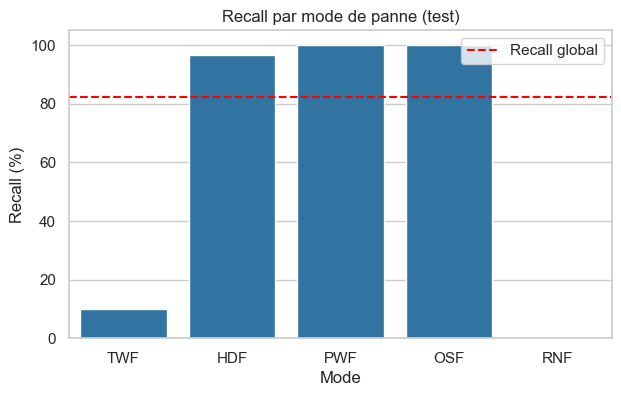

In [10]:
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
if same:
    te = clean.loc[Xte_raw.index, modes + ["Machine_failure"]].reset_index(drop=True)
    te["pred"] = pred_thr
    rows = []
    for m_ in modes:
        sub = te[te[m_] == 1]
        rows.append({"Mode": m_, "Pannes (test)": len(sub), "Détectées": int(sub["pred"].sum()),
                     "Ratées": int((1 - sub["pred"]).sum()),
                     "Recall (%)": round(sub["pred"].mean() * 100, 1) if len(sub) else np.nan})
    by_mode = pd.DataFrame(rows)
    display(by_mode)

    ok = by_mode.dropna()
    plt.figure(figsize=(7, 4))
    sns.barplot(data=ok, x="Mode", y="Recall (%)", color="tab:blue")
    plt.axhline(recall_score(y_test, pred_thr) * 100, color="red", linestyle="--", label="Recall global")
    plt.title("Recall par mode de panne (test)")
    plt.legend(); plt.ylim(0, 105)
    plt.savefig(FIG / "recall_par_mode.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("Split non reproductible : cette analyse est ignorée.")

**Lecture :**
- Un mode avec un recall élevé est bien capté par les variables (par ex. HDF et PWF, qui dépendent de seuils sur des variables créées).
- **RNF** est une panne aléatoire (0,1 %) : elle est impossible à prédire, donc le recall global ne peut pas atteindre 100 %.
- Si un mode a un recall bas, regarde ses signatures dans les KDE de l'EDA pour comprendre pourquoi.

## 10. Sauvegarde des résultats pour le rapport

In [11]:
final.to_csv(DATA / "evaluation_finale.csv")
ci.to_csv(DATA / "evaluation_intervalles.csv")
err.to_csv(DATA / "evaluation_erreurs.csv", index=False)
if same:
    by_mode.to_csv(DATA / "evaluation_par_mode.csv", index=False)
print("Fichiers sauvegardés dans", DATA, "et figures dans", FIG)

Fichiers sauvegardés dans c:\Users\ghait\Desktop\Projet Python\data et figures dans c:\Users\ghait\Desktop\Projet Python\figures


## Résumé à retenir pour le rapport
1. Le meilleur modèle est choisi sur la **validation croisée**, pas sur le test.
2. Le Random Forest optimisé avec seuil ajusté fournit le compromis final precision / recall.
3. L'effet de la PCA est mesuré modèle par modèle (Δ F1, Δ Recall).
4. Les métriques ont une **incertitude** (bootstrap) car les pannes sont peu nombreuses.
5. Le recall dépend du **mode de panne** : RNF est imprévisible par nature.